In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
%matplotlib inline

FILE = "reviews.csv"
TEXT_COL = "review"
RATING_COL = "rating"

df = pd.read_csv(FILE).dropna(subset=[TEXT_COL]).copy()
df[TEXT_COL] = df[TEXT_COL].astype(str)
df.head()

,review_id,review,rating
0,1,"Amazing product, works perfectly!",5
1,2,"Terrible quality, broke in a day.",1
2,3,"It is okay, nothing special.",3
3,4,"Love it, totally worth the price!",5
4,5,"Worst purchase ever, waste of money.",1


## Step 1: Score each review (NLP lexicon)

In [2]:
analyzer = SentimentIntensityAnalyzer()
df["compound"] = df[TEXT_COL].apply(lambda t: analyzer.polarity_scores(t)["compound"])
df[[TEXT_COL, "compound"]].head()

,review,compound
0,"Amazing product, works perfectly!",0.8516
1,"Terrible quality, broke in a day.",-0.7096
2,"It is okay, nothing special.",-0.0920
3,"Love it, totally worth the price!",0.7707
4,"Worst purchase ever, waste of money.",-0.7845


## Step 2: Classify as Positive, Negative or Neutral

In [3]:
def classify(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    return "Neutral"

df["sentiment"] = df["compound"].apply(classify)
df[[TEXT_COL, "compound", "sentiment"]]

,review,compound,sentiment
0,"Amazing product, works perfectly!",0.8516,Positive
1,"Terrible quality, broke in a day.",-0.7096,Negative
2,"It is okay, nothing special.",-0.0920,Negative
3,"Love it, totally worth the price!",0.7707,Positive
4,"Worst purchase ever, waste of money.",-0.7845,Negative
5,Good value and fast delivery.,0.6486,Positive
6,Not bad but the battery is weak.,-0.4451,Negative
7,"Absolutely fantastic, highly recommend!",0.8043,Positive
8,Poor packaging and late delivery.,-0.4767,Negative
9,Decent product for the price.,0.0000,Neutral


In [4]:
counts = df["sentiment"].value_counts()
print(counts)
print()
print((counts / len(df) * 100).round(1).astype(str) + "%")

sentiment
Negative    6
Positive    5
Neutral     1
Name: count, dtype: int64

sentiment
Negative    50.0%
Positive    41.7%
Neutral      8.3%
Name: count, dtype: object


## Step 3: Compare with star ratings

In [5]:
print(df.groupby(RATING_COL)["compound"].mean().round(2))
print()
print("Correlation (rating vs sentiment):", round(df[RATING_COL].corr(df["compound"]), 2))

rating
1   -0.70
2   -0.48
3   -0.18
4    0.65
5    0.82
Name: compound, dtype: float64

Correlation (rating vs sentiment): 0.97


## Step 4: Understand public opinion with charts

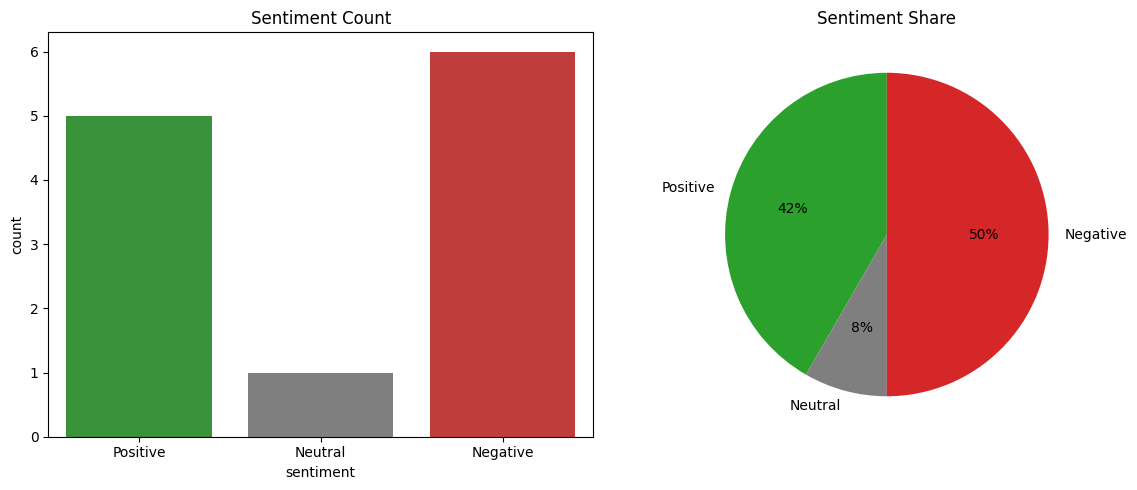

In [6]:
order = ["Positive", "Neutral", "Negative"]
colors = {"Positive": "#2ca02c", "Neutral": "#7f7f7f", "Negative": "#d62728"}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.countplot(x="sentiment", data=df, order=order, hue="sentiment", palette=colors, legend=False, ax=axes[0])
axes[0].set_title("Sentiment Count")
share = df["sentiment"].value_counts().reindex(order).fillna(0)
axes[1].pie(share, labels=order, autopct="%1.0f%%", colors=[colors[o] for o in order], startangle=90)
axes[1].set_title("Sentiment Share")
plt.tight_layout()
plt.savefig("sentiment_charts.png", dpi=150)
plt.show()

## Step 5: Insights for marketing and product

In [7]:
print("TOP 3 MOST POSITIVE REVIEWS (use in marketing):")
for t in df.nlargest(3, "compound")[TEXT_COL]:
    print("-", t)

print()
print("TOP 3 MOST NEGATIVE REVIEWS (problems to fix):")
for t in df.nsmallest(3, "compound")[TEXT_COL]:
    print("-", t)

pos = (df["sentiment"] == "Positive").mean() * 100
neg = (df["sentiment"] == "Negative").mean() * 100
print(f"\nInsight: {pos:.0f}% of customers are positive and {neg:.0f}% are negative.")

TOP 3 MOST POSITIVE REVIEWS (use in marketing):
- Amazing product, works perfectly!
- Superb sound quality, very happy.
- Absolutely fantastic, highly recommend!

TOP 3 MOST NEGATIVE REVIEWS (problems to fix):
- Worst purchase ever, waste of money.
- Terrible quality, broke in a day.
- Stopped working after a week, disappointed.

Insight: 42% of customers are positive and 50% are negative.


In [9]:
df.to_csv("reviews_with_sentiment.csv", index=False)
print("Saved reviews_with_sentiment.csv")

Saved reviews_with_sentiment.csv
